# Question 2


In [2]:
import numpy as np
import matplotlib.pyplot as plt

alpha = 2.0    # gravity coefficient (s^-1)
beta = 2.4     # feedback gain (s^-1)
gamma = 0.0    # constant bias (rad/s)

In [3]:
def posture_rhs(theta, alpha, beta, gamma):
    # Rate of change of the lean angle (rad/s)
    return alpha * np.sin(theta) - beta * theta - gamma

# Check: upright posture must be an equilibrium when gamma = 0
assert np.isclose(posture_rhs(0.0, alpha, beta, gamma), 0.0)
print("Check passed: f(0) = 0")

Check passed: f(0) = 0


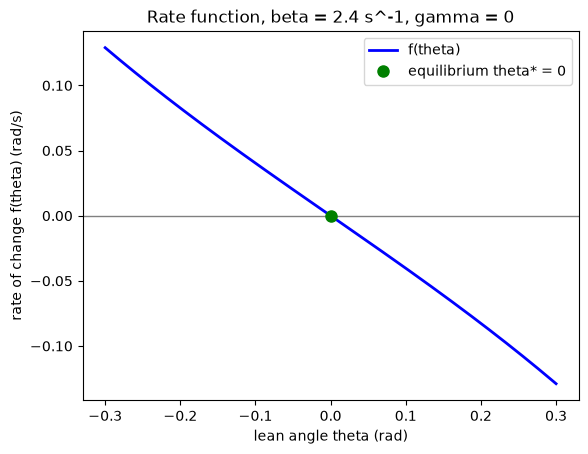

In [4]:
theta_grid = np.linspace(-0.30, 0.30, 500)
rates = posture_rhs(theta_grid, alpha, beta, gamma)

plt.plot(theta_grid, rates, color="blue", lw=2, label="f(theta)")
plt.axhline(0, color="grey", lw=1)
plt.plot(0, 0, "o", color="green", markersize=8, label="equilibrium theta* = 0")
plt.xlabel("lean angle theta (rad)")
plt.ylabel("rate of change f(theta) (rad/s)")
plt.title("Rate function, beta = 2.4 s^-1, gamma = 0")
plt.legend()
plt.savefig("figures/q2_rate_function.png", dpi=300, bbox_inches="tight")
plt.show()

# Question 3


In [5]:
h = 0.05          # time step (s)
t_end = 600.0     # simulation duration (s)
n_steps = int(t_end / h)                  # 12000 steps
time = np.linspace(0, t_end, n_steps + 1)


def euler(theta0, h, n_steps, alpha, beta, gamma):
    # Explicit Euler: theta_next = theta_now + h * f(theta_now)
    theta = np.zeros(n_steps + 1)
    theta[0] = theta0
    for k in range(n_steps):
        theta[k + 1] = theta[k] + h * posture_rhs(theta[k], alpha, beta, gamma)
    return theta


theta_neg = euler(-0.08, h, n_steps, alpha, beta, gamma)
theta_pos = euler(0.08, h, n_steps, alpha, beta, gamma)

# Check: both trajectories should end at the upright equilibrium
print("Final theta from -0.08:", theta_neg[-1])
print("Final theta from +0.08:", theta_pos[-1])
assert abs(theta_neg[-1]) < 1e-6 and abs(theta_pos[-1]) < 1e-6
print("Check passed: both converge to theta* = 0")

Final theta from -0.08: -4.119153441675105e-107
Final theta from +0.08: 4.119153441675105e-107
Check passed: both converge to theta* = 0


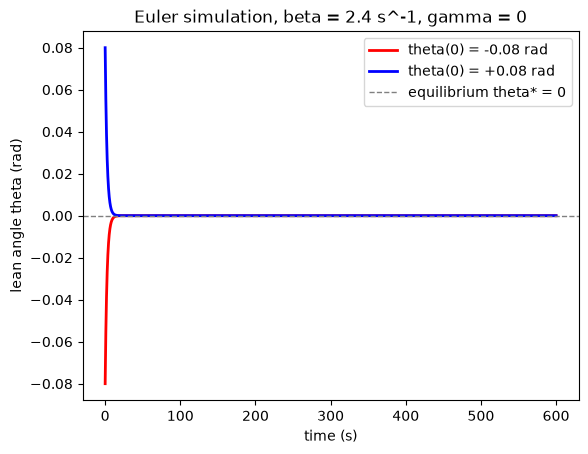

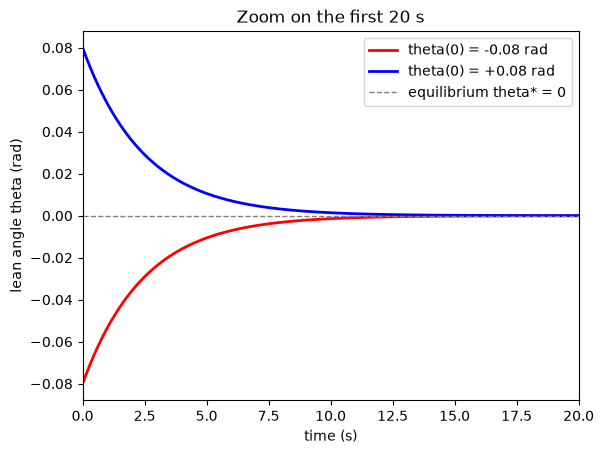

In [6]:
# Full simulation
plt.plot(time, theta_neg, color="red", lw=2, label="theta(0) = -0.08 rad")
plt.plot(time, theta_pos, color="blue", lw=2, label="theta(0) = +0.08 rad")
plt.axhline(0, color="grey", lw=1, ls="--", label="equilibrium theta* = 0")
plt.xlabel("time (s)")
plt.ylabel("lean angle theta (rad)")
plt.title("Euler simulation, beta = 2.4 s^-1, gamma = 0")
plt.legend()
plt.savefig("figures/q3_euler_full.png", dpi=300, bbox_inches="tight")
plt.show()

# Zoom on the first 20 s
plt.plot(time, theta_neg, color="red", lw=2, label="theta(0) = -0.08 rad")
plt.plot(time, theta_pos, color="blue", lw=2, label="theta(0) = +0.08 rad")
plt.axhline(0, color="grey", lw=1, ls="--", label="equilibrium theta* = 0")
plt.xlim(0, 20)
plt.xlabel("time (s)")
plt.ylabel("lean angle theta (rad)")
plt.title("Zoom on the first 20 s")
plt.legend()
plt.savefig("figures/q3_euler_zoom.png", dpi=300, bbox_inches="tight")
plt.show()